<a href="https://colab.research.google.com/github/rheahalebeed/BA305-A3-Billboard-Spotify-Project/blob/main/BA305ProjectCode.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
from google.colab import drive
drive.mount('/content/drive')
billboard = pd.read_csv("/content/drive/My Drive/BA 305 Project/billboard.csv")
audio_ft = pd.read_csv("/content/drive/My Drive/BA 305 Project/audio_features.csv")
billboard.head()

Mounted at /content/drive


,url,week_id,week_position,song,performer,song_id,instance,previous_week_position,peak_position,weeks_on_chart
0,http://www.billboard.com/charts/hot-100/1965-0...,7/17/1965,34,Don't Just Stand There,Patty Duke,Don't Just Stand TherePatty Duke,1,45.0,34,4
1,http://www.billboard.com/charts/hot-100/1965-0...,7/24/1965,22,Don't Just Stand There,Patty Duke,Don't Just Stand TherePatty Duke,1,34.0,22,5
2,http://www.billboard.com/charts/hot-100/1965-0...,7/31/1965,14,Don't Just Stand There,Patty Duke,Don't Just Stand TherePatty Duke,1,22.0,14,6
3,http://www.billboard.com/charts/hot-100/1965-0...,8/7/1965,10,Don't Just Stand There,Patty Duke,Don't Just Stand TherePatty Duke,1,14.0,10,7
4,http://www.billboard.com/charts/hot-100/1965-0...,8/14/1965,8,Don't Just Stand There,Patty Duke,Don't Just Stand TherePatty Duke,1,10.0,8,8


In [4]:
# Check the number of rows and columns in each dataset and count the unique songs
print("Billboard shape:", billboard.shape)
print("Audio features shape:", audio_ft.shape)
print("Unique Billboard songs:", billboard["song_id"].nunique())
print("Unique Audio songs:", audio_ft["song_id"].nunique())

Billboard shape: (327895, 10)
Audio features shape: (29503, 22)
Unique Billboard songs: 29389
Unique Audio songs: 29386


In [5]:
# Count the number of duplicate song IDs in the audio features dataset
print("Duplicate song_ids in audio features:", audio_ft["song_id"].duplicated().sum())

Duplicate song_ids in audio features: 117


In [6]:
# Display the first 20 rows with duplicate song IDs, sorted by song ID
audio_ft[audio_ft["song_id"].duplicated(keep=False)].sort_values("song_id").head(20)

,song_id,performer,song,spotify_genre,spotify_track_id,spotify_track_preview_url,spotify_track_duration_ms,spotify_track_explicit,spotify_track_album,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,spotify_track_popularity
344,24/7Meek Mill Featuring Ella Mai,Meek Mill Featuring Ella Mai,24/7,"['hip hop', 'philly rap', 'pop rap', 'rap', 's...",NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
345,24/7Meek Mill Featuring Ella Mai,Meek Mill Featuring Ella Mai,24/7,"['hip hop', 'philly rap', 'pop rap', 'rap', 's...",NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
540,A Holly Jolly ChristmasBurl Ives,Burl Ives,A Holly Jolly Christmas,"['adult standards', 'american folk revival']",65Q2mv3UlVi9eO70OpsmSe,NaN,135533.0,False,Have A Holly Jolly Christmas,0.683,...,-13.056,1.0,0.0303,0.57900,0.000000,0.0760,0.888,140.467,4.0,80.0
541,A Holly Jolly ChristmasBurl Ives,Burl Ives,A Holly Jolly Christmas,"['adult standards', 'american folk revival']",65Q2mv3UlVi9eO70OpsmSe,NaN,135533.0,False,Have A Holly Jolly Christmas,0.674,...,-12.937,1.0,0.0309,0.61600,0.000000,0.0781,0.862,140.352,4.0,82.0
803,Act UpCity Girls,City Girls,Act Up,"['pop', 'pop rap', 'trap queen']",3A2yGHWIzmGEIolwonU69h,NaN,158332.0,True,Girl Code,0.938,...,-4.713,1.0,0.1890,0.01670,0.000000,0.1110,0.313,97.075,4.0,79.0
804,Act UpCity Girls,City Girls,Act Up,"['pop', 'pop rap', 'trap queen']",3A2yGHWIzmGEIolwonU69h,NaN,158332.0,True,Girl Code,0.938,...,-4.713,1.0,0.1890,0.01670,0.000000,0.1110,0.313,97.075,4.0,80.0
1108,All I Want For Christmas Is YouMariah Carey,Mariah Carey,All I Want For Christmas Is You,"['dance pop', 'pop', 'r&b', 'urban contemporary']",0bYg9bo50gSsH3LtXe2SQn,https://p.scdn.co/mp3-preview/ab4f06069148ef85...,241106.0,False,Merry Christmas,0.335,...,-7.462,1.0,0.0386,0.16400,0.000000,0.0708,0.346,150.277,4.0,95.0
1109,All I Want For Christmas Is YouMariah Carey,Mariah Carey,All I Want For Christmas Is You,"['dance pop', 'pop', 'r&b', 'urban contemporary']",0bYg9bo50gSsH3LtXe2SQn,https://p.scdn.co/mp3-preview/ab4f06069148ef85...,241106.0,False,Merry Christmas,0.335,...,-7.462,1.0,0.0386,0.16400,0.000000,0.0708,0.346,150.277,4.0,97.0
1196,All The Good Girls Go To HellBillie Eilish,Billie Eilish,All The Good Girls Go To Hell,"['electropop', 'pop']",6IRdLKIyS4p7XNiP8r6rsx,NaN,168839.0,False,WHEN WE ALL FALL ASLEE,0.726,...,-8.922,0.0,0.3720,0.28300,0.143000,0.1770,0.569,185.044,4.0,86.0
1197,All The Good Girls Go To HellBillie Eilish,Billie Eilish,All The Good Girls Go To Hell,"['electropop', 'pop']",6IRdLKIyS4p7XNiP8r6rsx,NaN,168839.0,False,WHEN WE ALL FALL ASLEE,0.726,...,-8.922,0.0,0.3720,0.28300,0.143000,0.1770,0.569,185.044,4.0,87.0


In [7]:
# Group Billboard data by song ID to find each song's maximum weeks on the chart and best (lowest) peak position
billboard_song = billboard.groupby("song_id").agg(final_weeks_on_chart=("weeks_on_chart", "max"),
                                                  best_peak_position=("peak_position", "min")).reset_index()

In [8]:
# Check the number of rows and columns in the song-level Billboard dataset and display the first five rows
print("Billboard song-level shape:", billboard_song.shape)
billboard_song.head()

Billboard song-level shape: (29389, 3)


,song_id,final_weeks_on_chart,best_peak_position
0,"""B"" GirlsYoung And Restless",15,54
1,"""Cherry Cherry"" from Hot August NightNeil Diamond",10,31
2,"""Having A Party"" MedleyThe Ovations (Featuring...",9,56
3,"""Joy"" Pt. IIsaac Hayes",9,30
4,"""Roots"" MedleyQuincy Jones",7,57


In [9]:
# Merge the Billboard song-level data with audio features using matching song IDs
data = billboard_song.merge(audio_ft, on="song_id",how="inner")

In [10]:
# Check the number of rows and columns in the merged dataset and count the unique songs
print("Merged shape:", data.shape)
print("Unique songs:", data["song_id"].nunique())

Merged shape: (29500, 24)
Unique songs: 29383


In [11]:
# Identify duplicate song IDs in the merged dataset and display the first 30 rows with their song titles and performers
duplicates = data[data["song_id"].duplicated(keep=False)].sort_values("song_id")
duplicates[["song_id", "song", "performer"]].head(30)

,song_id,song,performer
340,24/7Meek Mill Featuring Ella Mai,24/7,Meek Mill Featuring Ella Mai
341,24/7Meek Mill Featuring Ella Mai,24/7,Meek Mill Featuring Ella Mai
537,A Holly Jolly ChristmasBurl Ives,A Holly Jolly Christmas,Burl Ives
538,A Holly Jolly ChristmasBurl Ives,A Holly Jolly Christmas,Burl Ives
807,Act UpCity Girls,Act Up,City Girls
808,Act UpCity Girls,Act Up,City Girls
1112,All I Want For Christmas Is YouMariah Carey,All I Want For Christmas Is You,Mariah Carey
1113,All I Want For Christmas Is YouMariah Carey,All I Want For Christmas Is You,Mariah Carey
1200,All The Good Girls Go To HellBillie Eilish,All The Good Girls Go To Hell,Billie Eilish
1201,All The Good Girls Go To HellBillie Eilish,All The Good Girls Go To Hell,Billie Eilish


In [12]:
# Count the number of song IDs with duplicates and show how many times each duplicated song ID appears
print("Number of duplicated song IDs:", duplicates["song_id"].nunique())
duplicates.groupby("song_id").size().value_counts()

Number of duplicated song IDs: 117


,count
2,117


In [13]:
duplicates.head(10).T

,340,341,537,538,807,808,1112,1113,1200,1201
song_id,24/7Meek Mill Featuring Ella Mai,24/7Meek Mill Featuring Ella Mai,A Holly Jolly ChristmasBurl Ives,A Holly Jolly ChristmasBurl Ives,Act UpCity Girls,Act UpCity Girls,All I Want For Christmas Is YouMariah Carey,All I Want For Christmas Is YouMariah Carey,All The Good Girls Go To HellBillie Eilish,All The Good Girls Go To HellBillie Eilish
final_weeks_on_chart,19,19,19,19,21,21,43,43,7,7
best_peak_position,54,54,4,4,26,26,1,1,46,46
performer,Meek Mill Featuring Ella Mai,Meek Mill Featuring Ella Mai,Burl Ives,Burl Ives,City Girls,City Girls,Mariah Carey,Mariah Carey,Billie Eilish,Billie Eilish
song,24/7,24/7,A Holly Jolly Christmas,A Holly Jolly Christmas,Act Up,Act Up,All I Want For Christmas Is You,All I Want For Christmas Is You,All The Good Girls Go To Hell,All The Good Girls Go To Hell
spotify_genre,"['hip hop', 'philly rap', 'pop rap', 'rap', 's...","['hip hop', 'philly rap', 'pop rap', 'rap', 's...","['adult standards', 'american folk revival']","['adult standards', 'american folk revival']","['pop', 'pop rap', 'trap queen']","['pop', 'pop rap', 'trap queen']","['dance pop', 'pop', 'r&b', 'urban contemporary']","['dance pop', 'pop', 'r&b', 'urban contemporary']","['electropop', 'pop']","['electropop', 'pop']"
spotify_track_id,NaN,NaN,65Q2mv3UlVi9eO70OpsmSe,65Q2mv3UlVi9eO70OpsmSe,3A2yGHWIzmGEIolwonU69h,3A2yGHWIzmGEIolwonU69h,0bYg9bo50gSsH3LtXe2SQn,0bYg9bo50gSsH3LtXe2SQn,6IRdLKIyS4p7XNiP8r6rsx,6IRdLKIyS4p7XNiP8r6rsx
spotify_track_preview_url,NaN,NaN,NaN,NaN,NaN,NaN,https://p.scdn.co/mp3-preview/ab4f06069148ef85...,https://p.scdn.co/mp3-preview/ab4f06069148ef85...,NaN,NaN
spotify_track_duration_ms,NaN,NaN,135533.0,135533.0,158332.0,158332.0,241106.0,241106.0,168839.0,168839.0
spotify_track_explicit,NaN,NaN,False,False,True,True,False,False,False,False


In [14]:
# Select the first duplicated song ID and display its audio feature records in a transposed format for comparison
example_id = duplicates["song_id"].iloc[0]
audio_ft[audio_ft["song_id"] == example_id].T

,344,345
song_id,24/7Meek Mill Featuring Ella Mai,24/7Meek Mill Featuring Ella Mai
performer,Meek Mill Featuring Ella Mai,Meek Mill Featuring Ella Mai
song,24/7,24/7
spotify_genre,"['hip hop', 'philly rap', 'pop rap', 'rap', 's...","['hip hop', 'philly rap', 'pop rap', 'rap', 's..."
spotify_track_id,NaN,NaN
spotify_track_preview_url,NaN,NaN
spotify_track_duration_ms,NaN,NaN
spotify_track_explicit,NaN,NaN
spotify_track_album,NaN,NaN
danceability,NaN,NaN


In [15]:
# Identify all rows with duplicate song IDs in the audio features dataset and sort them by song ID
audio_duplicates = audio_ft[audio_ft["song_id"].duplicated(keep=False)].sort_values("song_id")

In [16]:
# Check whether duplicated songs have different audio feature values and display the first example
audio_cols = ["danceability", "energy", "key", "loudness", "mode",
              "speechiness", "acousticness", "instrumentalness",
              "liveness", "valence", "tempo", "time_signature"]

for song_id in audio_duplicates["song_id"].unique():
    rows = audio_ft[audio_ft["song_id"] == song_id]

    if rows[audio_cols].nunique().max() > 1:
      print("Song ID:", song_id)
      display(rows[["song_id", "song", "performer", "spotify_track_id"] + audio_cols])
      break

Song ID: A Holly Jolly ChristmasBurl Ives


,song_id,song,performer,spotify_track_id,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
540,A Holly Jolly ChristmasBurl Ives,A Holly Jolly Christmas,Burl Ives,65Q2mv3UlVi9eO70OpsmSe,0.683,0.375,0.0,-13.056,1.0,0.0303,0.579,0.0,0.0760,0.888,140.467,4.0
541,A Holly Jolly ChristmasBurl Ives,A Holly Jolly Christmas,Burl Ives,65Q2mv3UlVi9eO70OpsmSe,0.674,0.370,0.0,-12.937,1.0,0.0309,0.616,0.0,0.0781,0.862,140.352,4.0


In [17]:
# Count how many duplicated songs have multiple Spotify track IDs versus only one unique Spotify track ID
id_counts = (audio_duplicates.groupby("song_id")["spotify_track_id"].nunique(dropna=True))
print("Duplicate songs with multiple Spotify track IDs:")
print((id_counts > 1).sum())
print("Duplicate songs with only one Spotify track ID:")
print((id_counts == 1).sum())

Duplicate songs with multiple Spotify track IDs:
0
Duplicate songs with only one Spotify track ID:
109


In [18]:
# Look for an example with multiple Spotify track IDs
for song_id in audio_duplicates["song_id"].unique():
    rows = audio_ft[audio_ft["song_id"] == song_id]

    if rows["spotify_track_id"].nunique(dropna=True) > 1:
        print("Song ID:", song_id)
        display(rows[["song_id", "song", "performer", "spotify_track_id"] + audio_cols])
        break

In [19]:
# How many duplicate song IDs have missing Spotify track IDs?
missing_track_id = (audio_duplicates.groupby("song_id")["spotify_track_id"].apply(lambda x: x.isna().all()))
print("Duplicate songs with completely missing Spotify track ID:",missing_track_id.sum())
print("Total duplicated song IDs:",
      len(audio_duplicates["song_id"].unique()))

Duplicate songs with completely missing Spotify track ID: 8
Total duplicated song IDs: 117


In [20]:
# Columns we want to average for duplicate Spotify records
audio_cols = ["danceability", "energy", "loudness",
              "speechiness", "acousticness", "instrumentalness",
              "liveness", "valence", "tempo",
              "spotify_track_duration_ms", "spotify_track_popularity"]

# Other columns that should stay the same
other_cols = ["key","mode","time_signature","performer","song","spotify_genre","spotify_track_id",
              "spotify_track_preview_url","spotify_track_explicit","spotify_track_album"]

# Average numeric audio features for each song
audio_numeric = (audio_ft.groupby("song_id")[audio_cols].mean().reset_index())

# Keep the first value for the non-numeric columns
audio_other = (audio_ft.groupby("song_id")[other_cols].first().reset_index())

# Combine them into one row per song
audio_clean = audio_other.merge(audio_numeric,on="song_id",how="left")

print("Original audio rows:", len(audio_ft))
print("Clean audio rows:", len(audio_clean))
print("Unique song IDs:", audio_clean["song_id"].nunique())

Original audio rows: 29503
Clean audio rows: 29386
Unique song IDs: 29386


In [21]:
# Check if any duplicate song IDs remain in the cleaned audio dataset
print("Duplicate song IDs:", audio_clean["song_id"].duplicated().sum())

Duplicate song IDs: 0


In [22]:
# Display the first five rows of the cleaned audio features dataset
audio_clean.head()

,song_id,key,mode,time_signature,performer,song,spotify_genre,spotify_track_id,spotify_track_preview_url,spotify_track_explicit,...,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,spotify_track_duration_ms,spotify_track_popularity
0,"""B"" GirlsYoung And Restless",7.0,1.0,3.0,Young And Restless,"""B"" Girls",[],0rWUHulFlScxQsCq7kWKde,https://p.scdn.co/mp3-preview/c551cbcaadd17bf4...,False,...,0.497,-11.913,0.439,0.0160,0.000000,0.312,0.769,193.762,242106.0,20.0
1,"""Cherry Cherry"" from Hot August NightNeil Diamond",9.0,1.0,4.0,Neil Diamond,"""Cherry Cherry"" from Hot August Night","['adult standards', 'brill building pop', 'fol...",18ocy9Be9SxWEEnOLGDfkS,None,False,...,0.948,-5.061,0.137,0.0941,0.000907,0.867,0.604,172.349,443320.0,16.0
2,"""Having A Party"" MedleyThe Ovations (Featuring...",NaN,NaN,NaN,The Ovations (Featuring Louis Williams),"""Having A Party"" Medley","['memphis soul', 'southern soul']",None,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,"""Joy"" Pt. IIsaac Hayes",NaN,NaN,NaN,Isaac Hayes,"""Joy"" Pt. I","['classic soul', 'disco', 'funk', 'jazz funk',...",None,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,"""Roots"" MedleyQuincy Jones",NaN,NaN,NaN,Quincy Jones,"""Roots"" Medley","['adult standards', 'disco', 'funk', 'jazz fun...",None,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


MERGING WITH BILLBOARD AFTER CLEANED

In [23]:
# Merge the cleaned datasets and check the final size, number of unique songs, and remaining duplicates
data = billboard_song.merge(audio_clean,
                            on="song_id",
                            how="inner")
print("Final dataset shape:", data.shape)
print("Unique songs:", data["song_id"].nunique())
print("Duplicate song IDs:", data["song_id"].duplicated().sum())

Final dataset shape: (29383, 24)
Unique songs: 29383
Duplicate song IDs: 0


In [24]:
# Display the first five rows of the final merged dataset
data.head()

,song_id,final_weeks_on_chart,best_peak_position,key,mode,time_signature,performer,song,spotify_genre,spotify_track_id,...,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,spotify_track_duration_ms,spotify_track_popularity
0,"""B"" GirlsYoung And Restless",15,54,7.0,1.0,3.0,Young And Restless,"""B"" Girls",[],0rWUHulFlScxQsCq7kWKde,...,0.497,-11.913,0.439,0.0160,0.000000,0.312,0.769,193.762,242106.0,20.0
1,"""Cherry Cherry"" from Hot August NightNeil Diamond",10,31,9.0,1.0,4.0,Neil Diamond,"""Cherry Cherry"" from Hot August Night","['adult standards', 'brill building pop', 'fol...",18ocy9Be9SxWEEnOLGDfkS,...,0.948,-5.061,0.137,0.0941,0.000907,0.867,0.604,172.349,443320.0,16.0
2,"""Having A Party"" MedleyThe Ovations (Featuring...",9,56,NaN,NaN,NaN,The Ovations (Featuring Louis Williams),"""Having A Party"" Medley","['memphis soul', 'southern soul']",None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,"""Joy"" Pt. IIsaac Hayes",9,30,NaN,NaN,NaN,Isaac Hayes,"""Joy"" Pt. I","['classic soul', 'disco', 'funk', 'jazz funk',...",None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,"""Roots"" MedleyQuincy Jones",7,57,NaN,NaN,NaN,Quincy Jones,"""Roots"" Medley","['adult standards', 'disco', 'funk', 'jazz fun...",None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [25]:
# Identify columns with missing values and display their missing counts and percentages, sorted from highest to lowest
missing = data.isna().sum()
missing_percent = (data.isna().mean() * 100).round(2)
missing_summary = pd.DataFrame({"missing_count": missing,"missing_percent": missing_percent})
missing_summary = missing_summary[missing_summary["missing_count"] > 0].sort_values("missing_percent", ascending=False)
missing_summary

,missing_count,missing_percent
spotify_track_preview_url,14956,50.90
mode,5159,17.56
key,5159,17.56
time_signature,5159,17.56
loudness,5159,17.56
energy,5159,17.56
danceability,5159,17.56
liveness,5159,17.56
instrumentalness,5159,17.56
acousticness,5159,17.56


In [26]:
#only looking at missing audio features
data[audio_cols].isna().sum()

,0
danceability,5159
energy,5159
loudness,5159
speechiness,5159
acousticness,5159
instrumentalness,5159
liveness,5159
valence,5159
tempo,5159
spotify_track_duration_ms,5097


In [27]:
#seeing how many songs have complete audio features vs missing all
print("Total songs:", len(data))
print("Songs with complete audio features:", data[audio_cols[:9]].notna().all(axis=1).sum())
print("Songs missing all audio features:", data[audio_cols[:9]].isna().all(axis=1).sum())

Total songs: 29383
Songs with complete audio features: 24224
Songs missing all audio features: 5159


In [28]:
# Count songs with and without missing audio characteristics
data["audio_missing"] = data[audio_cols[:9]].isna().any(axis=1)
data.groupby("audio_missing")[["final_weeks_on_chart", "best_peak_position"]].agg(["count", "mean", "median"])

final_weeks_on_chart                   best_peak_position  \
                             count       mean median              count   
audio_missing                                                             
False                        24224  11.733776   10.0              24224   
True                          5159   8.464431    7.0               5159   

                                 
                    mean median  
audio_missing                    
False          44.580086   43.0  
True           56.536150   61.0

In [29]:
# Remove songs with missing Spotify audio features

data_clean = data.dropna(subset=audio_cols[:9]).copy()

# Check how many songs remain

print("Original number of songs:", len(data))

print("Cleaned number of songs:", len(data_clean))

print("Songs removed:", len(data) - len(data_clean))

Original number of songs: 29383
Cleaned number of songs: 24224
Songs removed: 5159


In [30]:
data_clean[audio_cols[:9]].isna().sum()

,0
danceability,0
energy,0
loudness,0
speechiness,0
acousticness,0
instrumentalness,0
liveness,0
valence,0
tempo,0


# **Predictive Analysis**

In [31]:
# Select Spotify audio characteristics to predict Billboard chart longevity
features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

# Define the predictors and outcome variable
X = data_clean[features]
y = data_clean["final_weeks_on_chart"]

# Check the dimensions of the predictors and outcome
print("Predictors:", X.shape)
print("Outcome:", y.shape)

Predictors: (24224, 9)
Outcome: (24224,)


In [32]:
from sklearn.model_selection import train_test_split

# Split the data into 80% training and 20% testing

X_train, X_test, y_train, y_test = train_test_split(

    X, y, test_size=0.20, random_state=42

)

print("Training songs:", len(X_train))

print("Testing songs:", len(X_test))

Training songs: 19379
Testing songs: 4845


In [33]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)


LinearRegression()

In [34]:
# Predict Billboard chart longevity for songs in the testing dataset

y_pred = model.predict(X_test)

# Compare actual and predicted weeks on the Billboard Hot 100

predictions = pd.DataFrame({

    "Actual Weeks": y_test,

    "Predicted Weeks": y_pred

})

predictions.head(10)

,Actual Weeks,Predicted Weeks
21963,8,10.531690
21538,19,12.885682
23504,7,10.538614
10420,5,10.444296
15635,11,13.762750
18361,11,9.818828
4033,2,11.358627
19644,20,11.567398
5562,4,10.032901
3059,6,13.077796


In [35]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import numpy as np

# Evaluate how accurately Spotify audio characteristics predict Billboard chart longevity

r2 = r2_score(y_test, y_pred)

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("R²:", round(r2, 3))

print("MAE:", round(mae, 3))

print("RMSE:", round(rmse, 3))

R²: 0.058
MAE: 6.323
RMSE: 7.985


In [36]:
from sklearn.dummy import DummyRegressor

# Train a baseline model that predicts the average Billboard chart duration

baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

# Generate baseline predictions for the testing songs

baseline_pred = baseline.predict(X_test)

In [37]:
results = pd.DataFrame({

    "Model": ["Baseline", "Linear Regression"],

    "R²": [

        r2_score(y_test, baseline_pred),

        r2_score(y_test, y_pred)

    ],

    "MAE": [

        mean_absolute_error(y_test, baseline_pred),

        mean_absolute_error(y_test, y_pred)

    ],

    "RMSE": [

        np.sqrt(mean_squared_error(y_test, baseline_pred)),

        np.sqrt(mean_squared_error(y_test, y_pred))

    ]

})

results.round(3)

,Model,R²,MAE,RMSE
0,Baseline,-0.000,6.597,8.228
1,Linear Regression,0.058,6.323,7.985


In [38]:
# Examine how each Spotify audio characteristic relates to Billboard chart longevity

coefficients = pd.DataFrame({

    "Audio Feature": X.columns,

    "Coefficient": model.coef_

})

coefficients.sort_values("Coefficient", ascending=False)

,Audio Feature,Coefficient
0,danceability,6.484565
2,loudness,0.196513
8,tempo,0.000329
1,energy,-1.022898
6,liveness,-1.501947
5,instrumentalness,-1.975449
7,valence,-2.250208
4,acousticness,-3.876331
3,speechiness,-10.227564


In [39]:
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression

# Standardize audio characteristics using the training data

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

# Train regression using standardized audio characteristics

model_scaled = LinearRegression()

model_scaled.fit(X_train_scaled, y_train)

# Compare standardized coefficients across audio characteristics

standardized_coefficients = pd.DataFrame({

    "Audio Feature": X.columns,

    "Standardized Coefficient": model_scaled.coef_

})

standardized_coefficients.sort_values(

    "Standardized Coefficient",

    key=abs,

    ascending=False

)

,Audio Feature,Standardized Coefficient
4,acousticness,-1.093668
0,danceability,0.991800
3,speechiness,-0.848005
2,loudness,0.707686
7,valence,-0.537097
5,instrumentalness,-0.268780
6,liveness,-0.240139
1,energy,-0.203109
8,tempo,0.009229


In [40]:
from sklearn.preprocessing import StandardScaler

# Standardize audio characteristics for k-NN regression

scaler_knn = StandardScaler()

X_train_knn = scaler_knn.fit_transform(X_train)

X_test_knn = scaler_knn.transform(X_test)

In [41]:
from sklearn.neighbors import KNeighborsRegressor

# Train a k-NN regression model using five nearest neighbors

knn_model = KNeighborsRegressor(n_neighbors=5)

knn_model.fit(X_train_knn, y_train)

# Predict Billboard chart longevity

knn_pred = knn_model.predict(X_test_knn)

In [42]:
from sklearn.model_selection import GridSearchCV

from sklearn.pipeline import make_pipeline

# Compare different numbers of neighbors using cross-validation

knn_search = GridSearchCV(

    make_pipeline(StandardScaler(), KNeighborsRegressor()),

    param_grid={"kneighborsregressor__n_neighbors": [5, 10, 20, 50]},

    cv=3,

    scoring="neg_mean_absolute_error",

    n_jobs=-1

)

knn_search.fit(X_train, y_train)

print("Best k:", knn_search.best_params_)

Best k: {'kneighborsregressor__n_neighbors': 50}


In [43]:
# Use the best k-NN model to predict chart longevity

knn_model = knn_search.best_estimator_

knn_pred = knn_model.predict(X_test)

Regression Tree

In [44]:
from sklearn.tree import DecisionTreeRegressor

# Train a regression tree to predict Billboard chart longevity

tree_model = DecisionTreeRegressor(

    max_depth=5,

    random_state=42

)

tree_model.fit(X_train, y_train)

# Predict Billboard chart longevity

tree_pred = tree_model.predict(X_test)

In [45]:
from sklearn.tree import DecisionTreeRegressor

# Train a regression tree to predict Billboard chart longevity

tree_model = DecisionTreeRegressor(

    max_depth=5,

    random_state=42

)

tree_model.fit(X_train, y_train)

# Predict Billboard chart longevity

tree_pred = tree_model.predict(X_test)
# Compare regression tree depths using cross-validation

tree_search = GridSearchCV(

    DecisionTreeRegressor(random_state=42),

    param_grid={"max_depth": [3, 5, 7, 10]},

    cv=3,

    scoring="neg_mean_absolute_error",

    n_jobs=-1

)

tree_search.fit(X_train, y_train)

print("Best tree depth:", tree_search.best_params_)

Best tree depth: {'max_depth': 5}


In [46]:
import pandas as pd

import numpy as np

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Compare baseline, k-NN, and regression tree prediction accuracy

results = pd.DataFrame({

    "Model": ["Baseline", "k-NN Regression", "Regression Tree"],

    "R²": [

        r2_score(y_test, baseline_pred),

        r2_score(y_test, knn_pred),

        r2_score(y_test, tree_pred)

    ],

    "MAE": [

        mean_absolute_error(y_test, baseline_pred),

        mean_absolute_error(y_test, knn_pred),

        mean_absolute_error(y_test, tree_pred)

    ],

    "RMSE": [

        np.sqrt(mean_squared_error(y_test, baseline_pred)),

        np.sqrt(mean_squared_error(y_test, knn_pred)),

        np.sqrt(mean_squared_error(y_test, tree_pred))

    ]

})

results.round(3)

,Model,R²,MAE,RMSE
0,Baseline,-0.000,6.597,8.228
1,k-NN Regression,0.059,6.290,7.980
2,Regression Tree,0.036,6.374,8.081


 Additional analysis: multiple linear regression

In [47]:
from sklearn.linear_model import LinearRegression

# Train multiple linear regression using Spotify audio characteristics

model = LinearRegression()

model.fit(X_train, y_train)

# Generate predictions

y_pred = model.predict(X_test)

In [48]:
# Evaluate linear regression prediction accuracy

print("R²:", round(r2_score(y_test, y_pred), 3))

print("MAE:", round(mean_absolute_error(y_test, y_pred), 3))

print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 3))

R²: 0.058
MAE: 6.323
RMSE: 7.985


In [49]:
# Examine relationships between audio characteristics and chart longevity

coefficients = pd.DataFrame({

    "Audio Feature": X.columns,

    "Coefficient": model.coef_

})

coefficients.sort_values("Coefficient", ascending=False)

,Audio Feature,Coefficient
0,danceability,6.484565
2,loudness,0.196513
8,tempo,0.000329
1,energy,-1.022898
6,liveness,-1.501947
5,instrumentalness,-1.975449
7,valence,-2.250208
4,acousticness,-3.876331
3,speechiness,-10.227564


In [50]:
# Standardize predictors to compare regression coefficients

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

model_scaled = LinearRegression()

model_scaled.fit(X_train_scaled, y_train)

standardized_coefficients = pd.DataFrame({

    "Audio Feature": X.columns,

    "Standardized Coefficient": model_scaled.coef_

})

standardized_coefficients.sort_values(

    "Standardized Coefficient",

    key=abs,

    ascending=False

)

,Audio Feature,Standardized Coefficient
4,acousticness,-1.093668
0,danceability,0.991800
3,speechiness,-0.848005
2,loudness,0.707686
7,valence,-0.537097
5,instrumentalness,-0.268780
6,liveness,-0.240139
1,energy,-0.203109
8,tempo,0.009229


ADDITIONAL DATA INVESTIGATION 10/23

In [52]:
# Summary statistics for weeks on chart

data["final_weeks_on_chart"].describe()


,final_weeks_on_chart
count,29383.000000
mean,11.159752
std,8.280146
min,1.000000
25%,5.000000
50%,10.000000
75%,16.000000
max,87.000000


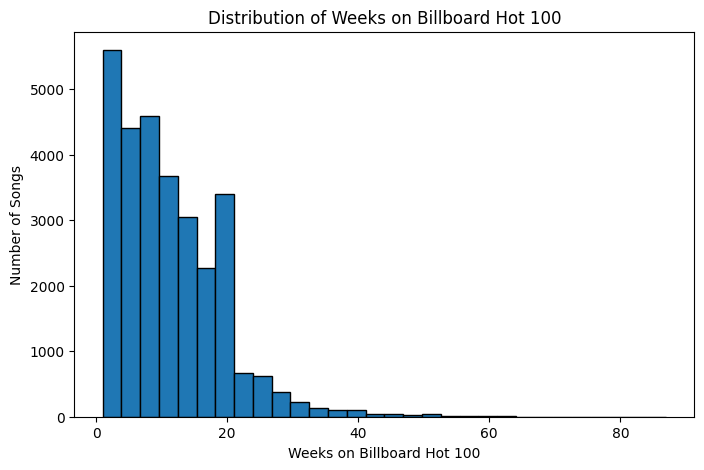

In [59]:
#Plot the distribution of weeks on chart

plt.figure(figsize=(8, 5))

plt.hist(data["final_weeks_on_chart"], bins=30, edgecolor="black")

plt.xlabel("Weeks on Billboard Hot 100")

plt.ylabel("Number of Songs")

plt.title("Distribution of Weeks on Billboard Hot 100")

plt.show()

In [51]:
# Find the 10 songs with the longest chart runs
data.nlargest(10, "final_weeks_on_chart")

,song_id,final_weeks_on_chart,best_peak_position,key,mode,time_signature,performer,song,spotify_genre,spotify_track_id,...,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,spotify_track_duration_ms,spotify_track_popularity,audio_missing
19477,RadioactiveImagine Dragons,87,3,9.0,1.0,4.0,Imagine Dragons,Radioactive,['modern rock'],4G8gkOterJn0Ywt6uhqbhp,...,-3.686,0.0627,0.10600,0.000108,0.6680,0.236,136.245,186813.0,74.0,False
20471,SailAWOLNATION,79,17,1.0,1.0,4.0,AWOLNATION,Sail,"['indie pop', 'la indie', 'modern alternative ...",5xhQChGGhKLWqBqX4XhtYE,...,-9.582,0.0568,0.45200,0.609000,0.0953,0.243,119.038,259102.0,74.0,False
2874,Blinding LightsThe Weeknd,76,1,1.0,1.0,4.0,The Weeknd,Blinding Lights,"['canadian contemporary r&b', 'canadian pop', ...",0sf12qNH5qcw8qpgymFOqD,...,-4.075,0.0629,0.00147,0.000209,0.0938,0.345,171.017,201573.0,96.0,False
12101,I'm YoursJason Mraz,76,6,11.0,1.0,4.0,Jason Mraz,I'm Yours,"['acoustic pop', 'neo mellow', 'pop', 'pop rock']",1EzrEOXmMH3G43AXT1y7pA,...,-8.322,0.0468,0.59500,0.000000,0.1050,0.718,150.953,242186.0,83.0,False
10186,How Do I LiveLeAnn Rimes,69,2,2.0,1.0,4.0,LeAnn Rimes,How Do I Live,"['country', 'country dawn', 'dance pop', 'pop ...",7BD50ATrF3Vab5FQy7vtK8,...,-7.989,0.0279,0.12800,0.000000,0.0822,0.258,128.303,266973.0,68.0,False
4621,Counting StarsOneRepublic,68,2,1.0,0.0,4.0,OneRepublic,Counting Stars,"['dance pop', 'neo mellow', 'piano rock', 'pop...",6sy3LkhNFjJWlaeSMNwQ62,...,-4.972,0.0382,0.06540,0.000000,0.1150,0.477,122.017,257839.0,75.0,False
18683,Party Rock AnthemLMFAO Featuring Lauren Bennet...,68,1,5.0,0.0,4.0,LMFAO Featuring Lauren Bennett & GoonRock,Party Rock Anthem,"['dance pop', 'pop', 'pop rap']",0IkKz2J93C94Ei4BvDop7P,...,-4.210,0.1420,0.01890,0.000000,0.2660,0.359,129.993,262173.0,68.0,False
7430,Foolish Games/You Were Meant For MeJewel,65,2,NaN,NaN,NaN,Jewel,Foolish Games/You Were Meant For Me,"['alaska indie', 'lilith', 'permanent wave', '...",None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
20182,Rolling In The DeepAdele,65,1,8.0,1.0,4.0,Adele,Rolling In The Deep,"['british soul', 'pop', 'uk pop']",1CkvWZme3pRgbzaxZnTl5X,...,-5.119,0.0294,0.13100,0.000000,0.0527,0.522,104.945,228293.0,76.0,False
2477,Before He CheatsCarrie Underwood,64,8,6.0,0.0,4.0,Carrie Underwood,Before He Cheats,"['contemporary country', 'country', 'country d...",0ZUo4YjG4saFnEJhdWp9Bt,...,-3.318,0.0405,0.27100,0.000000,0.1190,0.290,147.905,199946.0,74.0,False


Our outcome variable is right-skewed, with most songs remaining on the Billboard Hot 100 for relatively short periods and a small number remaining substantially longer. This could contribute to prediction errors, particularly for unusually successful songs.

In [54]:
# Compare actual weeks with k-NN predictions

errors = X_test.copy()

errors["actual_weeks"] = y_test

errors["predicted_weeks"] = knn_pred

# Calculate the size of each prediction error

errors["absolute_error"] = abs(

    errors["actual_weeks"] - errors["predicted_weeks"]

)

# Display the 10 largest errors

errors.nlargest(10, "absolute_error")

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,actual_weeks,predicted_weeks,absolute_error
26347,0.367,0.215,-16.652,0.0288,0.51700,0.000000,0.618,0.266,98.742,57,8.92,48.08
16400,0.677,0.484,-10.506,0.0324,0.07700,0.000048,0.135,0.697,123.534,55,11.14,43.86
29249,0.596,0.854,-5.114,0.4630,0.01690,0.000000,0.124,0.152,120.274,48,6.14,41.86
5866,0.532,0.869,-5.094,0.1720,0.15700,0.005080,0.136,0.422,159.803,52,11.10,40.90
27286,0.527,0.671,-5.032,0.0283,0.00842,0.000000,0.268,0.331,136.030,51,12.18,38.82
19064,0.679,0.715,-6.383,0.0407,0.07550,0.000000,0.271,0.571,127.435,53,14.40,38.60
2605,0.680,0.563,-5.843,0.0454,0.35400,0.000000,0.136,0.374,145.028,52,15.86,36.14
25983,0.746,0.873,-3.803,0.1280,0.02440,0.000000,0.354,0.817,148.075,52,15.90,36.10
18595,0.720,0.748,-5.522,0.3930,0.02350,0.000000,0.369,0.246,145.220,40,5.28,34.72
2523,0.776,0.780,-4.374,0.1280,0.06220,0.000000,0.081,0.666,124.949,51,16.38,34.62


In [55]:
# Group songs based on actual chart duration

errors["chart_group"] = pd.cut(

    errors["actual_weeks"],

    bins=[0, 5, 10, 20, float("inf")],

    labels=["1-5", "6-10", "11-20", "21+"]

)

# Calculate average prediction error for each group

errors.groupby("chart_group", observed=True)["absolute_error"].mean()

,absolute_error
chart_group,
1-5,8.829842
6-10,3.339481
11-20,4.127894
21+,14.099121


In [56]:
# Calculate the direction of prediction errors

errors["prediction_error"] = (

    errors["predicted_weeks"] - errors["actual_weeks"]

)

# Compare average prediction errors across chart-duration groups

errors.groupby("chart_group", observed=True)["prediction_error"].mean()

,prediction_error
chart_group,
1-5,8.829842
6-10,3.161229
11-20,-3.521128
21+,-14.099121


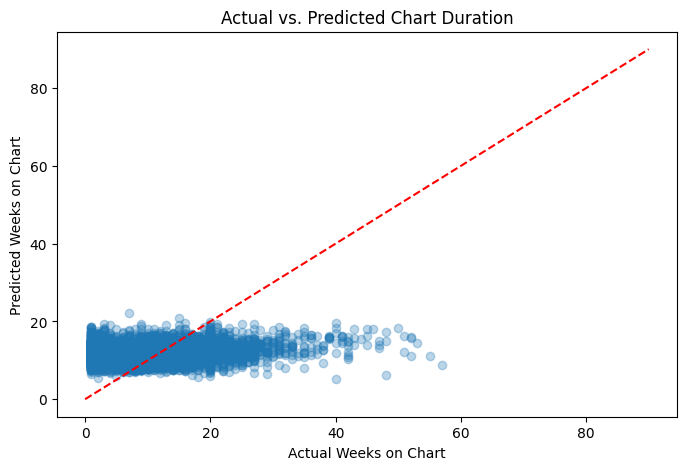

In [58]:
# Compare actual and predicted chart durations

plt.figure(figsize=(8, 5))

plt.scatter(

    errors["actual_weeks"],

    errors["predicted_weeks"],

    alpha=0.3

)

# Add a reference line showing perfect predictions

plt.plot([0, 90], [0, 90], linestyle="--", color="red")

plt.xlabel("Actual Weeks on Chart")

plt.ylabel("Predicted Weeks on Chart")

plt.title("Actual vs. Predicted Chart Duration")

plt.show()

In [ ]:
t

Address Missing Data Improvements

In [60]:
# Count missing audio features for each song

missing_counts = data[audio_cols[:9]].isna().sum(axis=1)

# Show how many songs have 0, 1, 2, etc. missing features

missing_counts.value_counts().sort_index()

,count
0,24224
9,5159


In [61]:
# Select songs missing all nine audio characteristics

missing_songs = data[data[audio_cols[:9]].isna().all(axis=1)]

# Check whether these songs have genre information

print("Total missing songs:", len(missing_songs))

print("Songs with genre information:",

      missing_songs["spotify_genre"].notna().sum())

print("Songs without genre information:",

      missing_songs["spotify_genre"].isna().sum())

Total missing songs: 5159
Songs with genre information: 3707
Songs without genre information: 1452


In [62]:
# Look at genre information for songs missing audio features

missing_songs["spotify_genre"].head(10)

,spotify_genre
2,"['memphis soul', 'southern soul']"
3,"['classic soul', 'disco', 'funk', 'jazz funk',..."
4,"['adult standards', 'disco', 'funk', 'jazz fun..."
5,None
13,"['east coast hip hop', 'hip hop', 'pop rap', '..."
15,['english indie rock']
16,[]
23,[]
25,['rif']
26,[]


In [63]:
# Find the most common genre values

missing_songs["spotify_genre"].value_counts().head(10)

,count
spotify_genre,
[],1106
"['east coast hip hop', 'hip hop', 'pop rap', 'rap', 'southern hip hop']",38
['deep adult standards'],36
"['adult standards', 'classic soul', 'jazz blues', 'piano blues', 'soul', 'soul blues', 'vocal jazz']",35
"['adult standards', 'brill building pop', 'easy listening', 'lounge', 'rock-and-roll', 'rockabilly']",34
['brill building pop'],24
"['adult standards', 'brill building pop', 'deep adult standards', 'easy listening', 'lounge', 'vocal jazz']",21
"['funk', 'motown', 'soul']",21
['bubblegum pop'],19


In [64]:
import ast

# Extract the first genre from each song's genre list

def get_first_genre(value):

    if isinstance(value, str):

        try:

            value = ast.literal_eval(value)

        except (ValueError, SyntaxError):

            return None

    if isinstance(value, (list, tuple)) and len(value) > 0:

        return value[0]

    return None

# Create a simplified genre column

data["first_genre"] = data["spotify_genre"].apply(get_first_genre)

# Check the most common first genres

data["first_genre"].value_counts().head(15)

,count
first_genre,
adult standards,3708
album rock,2318
dance pop,2222
contemporary country,1361
brill building pop,1032
classic soul,1030
atl hip hop,526
disco,395
bubblegum pop,385


In [65]:
# Select songs with complete Spotify audio characteristics

complete_songs = data[data[audio_cols[:9]].notna().all(axis=1)]

# Count complete songs in each genre

genre_counts = complete_songs["first_genre"].value_counts()

# Display the 15 most common genres

genre_counts.head(15)


,count
first_genre,
adult standards,3201
album rock,2195
dance pop,2092
contemporary country,1327
classic soul,904
brill building pop,899
atl hip hop,497
disco,363
pop,345


In [66]:
from sklearn.model_selection import train_test_split

# Split complete songs into reference and validation groups

reference_songs, validation_songs = train_test_split(

    complete_songs,

    test_size=0.20,

    random_state=42

)

print("Reference songs:", len(reference_songs))

print("Validation songs:", len(validation_songs))

Reference songs: 19379
Validation songs: 4845
